<a href="https://colab.research.google.com/github/Raquelodaka/Previsao-de-Churn-de-Clientes-e-Estrat-gia-de-Retencao.ipynb/blob/main/Previs%C3%A3o_de_Churn_de_Clientes_e_Estrat%C3%A9gia_de_Reten%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset: Bank Customer Churn Dataset (Kaggle).

###Previsão de Churn de Clientes e Estratégia de Retenção

---


Prever quais clientes têm alta probabilidade de cancelar serviços ou migrar de banco nos próximos 30 a 90 dias, segmentando-os por Valor de Vida do Cliente (CLV).

Unir a predição da probabilidade de cancelamento ao impacto financeiro para direcionar estratégias de retenção eficazes.

Técnicas:

Análise de sobrevivência (Survival Analysis) ou modelos de classificação binária temporal.

Clustering (K-Means, DBSCAN) para segmentação comportamental pós-predição.

Análise de importância de atributos temporais (frequência de uso do app, queda em saldo médio).

Diferencial de Negócio: Propor campanhas específicas por cluster (ex: oferecer isenção de taxa para clientes com alto CLV vs. push de engajamento para baixo CLV).

Bank Customer Churn Dataset (Kaggle).

In [ ]:
#Biblitecas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split


In [ ]:
df = pd.read_csv('/content/Customer-Churn-Records.csv')
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,0,1,DIAMOND,300
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,5,PLATINUM,771
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,3,SILVER,564
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,1,2,GOLD,339


In [ ]:
# Exibe o resumo com nomes, contagem de nulos e tipos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [ ]:
# Dicionário com a tradução e padronização dos nomes
mapeamento_colunas = {
    'RowNumber': 'Numero_Linha',
    'CustomerId': 'ID_Cliente',
    'Surname': 'Sobrenome',
    'CreditScore': 'Score_Credito',
    'Geography': 'Pais',
    'Gender': 'Genero',
    'Age': 'Idade',
    'Tenure': 'Anos_Como_Cliente',
    'Balance': 'Saldo_Conta',
    'NumOfProducts': 'Num_Produtos',
    'HasCrCard': 'Possui_Cartao_Credito',
    'IsActiveMember': 'Membro_Ativo',
    'EstimatedSalary': 'Salario_Estimado',
    'Exited': 'Churn',  #  Churn (0 = Não, 1 = Sim)
    'Complain': 'Fez_Reclamacao',
    'Satisfaction Score': 'Score_Satisfacao',
    'Card Type': 'Tipo_Cartao',
    'Point Earned': 'Pontos_Acumulados',
}

# Aplicar a alteração no DataFrame
df = df.rename(columns=mapeamento_colunas)

# Verificar se os nomes foram alterados com sucesso
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Numero_Linha           10000 non-null  int64  
 1   ID_Cliente             10000 non-null  int64  
 2   Sobrenome              10000 non-null  object 
 3   Score_Credito          10000 non-null  int64  
 4   Pais                   10000 non-null  object 
 5   Genero                 10000 non-null  object 
 6   Idade                  10000 non-null  int64  
 7   Anos_Como_Cliente      10000 non-null  int64  
 8   Saldo_Conta            10000 non-null  float64
 9   Num_Produtos           10000 non-null  int64  
 10  Possui_Cartao_Credito  10000 non-null  int64  
 11  Membro_Ativo           10000 non-null  int64  
 12  Salario_Estimado       10000 non-null  float64
 13  Churn                  10000 non-null  int64  
 14  Fez_Reclamacao         10000 non-null  int64  
 15  Sco

In [ ]:
# Remover a coluna diretamente no DataFrame (inplace=True)
df.drop(columns=['Numero_Linha'], inplace=True)

# Verificar se a coluna foi removida com sucesso
df.head(2)

,ID_Cliente,Sobrenome,Score_Credito,Pais,Genero,Idade,Anos_Como_Cliente,Saldo_Conta,Num_Produtos,Possui_Cartao_Credito,Membro_Ativo,Salario_Estimado,Churn,Fez_Reclamacao,Score_Satisfacao,Tipo_Cartao,Pontos_Acumulados
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456


## Feature Engineering

Indicador de Reserva Financeira

- ['Saldo_Conta'] / ['Salario_Estimado'] + 1: Divido o saldo mantido em conta pelo salário estimado do cliente o resultado será inserido na variavel ['Reserva_Saldo_Salario']
  - o '+ 1' inserido no calculo trata-se de uma proteção matemática para evitar o erro de divisão por zero caso algum cliente tenha o salário cadastrado como $0$.
- O 'round(..., 4)': Arredonda o resultado do cálculo para 4 casas decimais, a fim de manter o DataFrame limpo e legível.

In [ ]:
# Indicador de Reserva Financera (Saldo vs Salário)
df['Reserva_Saldo_Salario'] = np.round(
    df['Saldo_Conta'] / (df['Salario_Estimado'] + 1), 4
)

df

,ID_Cliente,Sobrenome,Score_Credito,Pais,Genero,Idade,Anos_Como_Cliente,Saldo_Conta,Num_Produtos,Possui_Cartao_Credito,Membro_Ativo,Salario_Estimado,Churn,Fez_Reclamacao,Score_Satisfacao,Tipo_Cartao,Pontos_Acumulados,Reserva_Saldo_Salario
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,0.0000
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0.7447
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377,1.4014
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350,0.0000
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425,1.5870
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,0,1,DIAMOND,300,0.0000
9996,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,5,PLATINUM,771,0.5641
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,3,SILVER,564,0.0000
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,1,2,GOLD,339,0.8082


/tmp/ipykernel_1328/3468513211.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


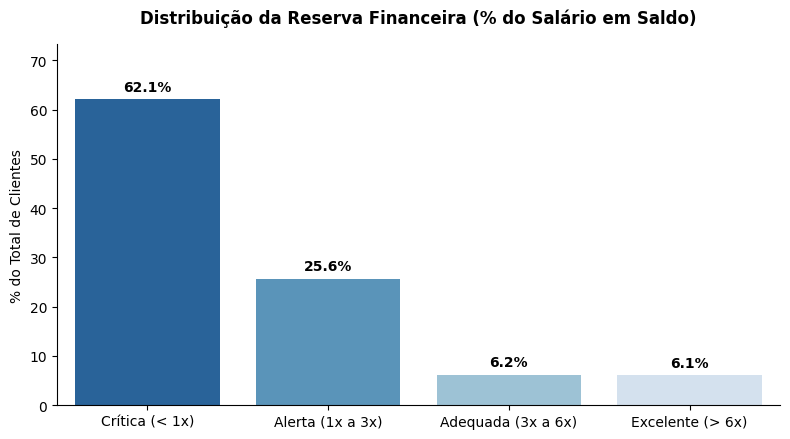

In [ ]:
# Categorizar o indicador em faixas práticas
bins = [-np.inf, 1, 3, 6, np.inf]
labels = [
    'Crítica (< 1x)',
    'Alerta (1x a 3x)',
    'Adequada (3x a 6x)',
    'Excelente (> 6x)',
]
df['Faixa_Reserva'] = pd.cut(
    df['Reserva_Saldo_Salario'], bins=bins, labels=labels
)

# Calcular a proporção (%) por faixa
resumo = df['Faixa_Reserva'].value_counts(normalize=True).reindex(labels) * 100

# Gerar o gráfico limpo
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    x=resumo.index, y=resumo.values, palette='Blues_r', edgecolor='none'
)

# Estilização para clareza visual
plt.title(
    'Distribuição da Reserva Financeira (% do Salário em Saldo)',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.ylabel('% do Total de Clientes')
plt.xlabel('')
plt.ylim(0, max(resumo.values) * 1.18)

# Adicionar os rótulos numéricos no topo das barras
for p in ax.patches:
  height = p.get_height()
  if not np.isnan(height):
    ax.annotate(
        f'{height:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontweight='bold',
    )

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

Engajamento Cliente

Flag binária (0 ou 1) chamada Risco_Engajamento para mapear clientes com perfil de alto risco de desengajamento
- '['Membro_Ativo'] == 0': Verifica se o cliente não está ativo nos canais digitais do banco (internet banking ou aplicativo).
- '['Num_Produtos'] == 1': Usa o operador lógico "E" (&) para checar se o cliente possui apenas 1 produto contratado na instituição.
- Retorna 1 se o cliente preencher ambos os critérios ao mesmo tempo (Inativo + 1 Único Produto). Retorna 0 para qualquer outra combinação.
- '['Risco_Engajamento'] = ...': armazena o valor da condição da flag criada 0 para clientes.
  - Cliente Risco_Engajamento = 1: É o perfil de maior vulnerabilidade. Ele não tem vínculo forte com o banco (apenas um produto) e já parou de usar os canais no dia a dia. É o cliente "silencioso" que provavelmente já migrou para a concorrência e só falta encerrar a conta.
  - Cliente Risco_Engajamento = 0: É um cliente engajado ou que possui múltiplos produtos (o que aumenta o custo de troca e dificulta o cancelamento).

In [ ]:
# Proxy de Risco de Engajamento Temporal (Cliente Inativo sem múltiplos produtos)
df['Risco_Engajamento'] = np.where(
    (df['Membro_Ativo'] == 0) & (df['Num_Produtos'] == 1), 1, 0
)

df

,ID_Cliente,Sobrenome,Score_Credito,Pais,Genero,Idade,Anos_Como_Cliente,Saldo_Conta,Num_Produtos,Possui_Cartao_Credito,Membro_Ativo,Salario_Estimado,Churn,Fez_Reclamacao,Score_Satisfacao,Tipo_Cartao,Pontos_Acumulados,Reserva_Saldo_Salario,Faixa_Reserva,Risco_Engajamento
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,0.0000,Crítica (< 1x),0
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0.7447,Crítica (< 1x),0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377,1.4014,Alerta (1x a 3x),0
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350,0.0000,Crítica (< 1x),0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425,1.5870,Alerta (1x a 3x),0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,0,1,DIAMOND,300,0.0000,Crítica (< 1x),0
9996,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,5,PLATINUM,771,0.5641,Crítica (< 1x),0
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,3,SILVER,564,0.0000,Crítica (< 1x),0
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,1,2,GOLD,339,0.8082,Crítica (< 1x),0


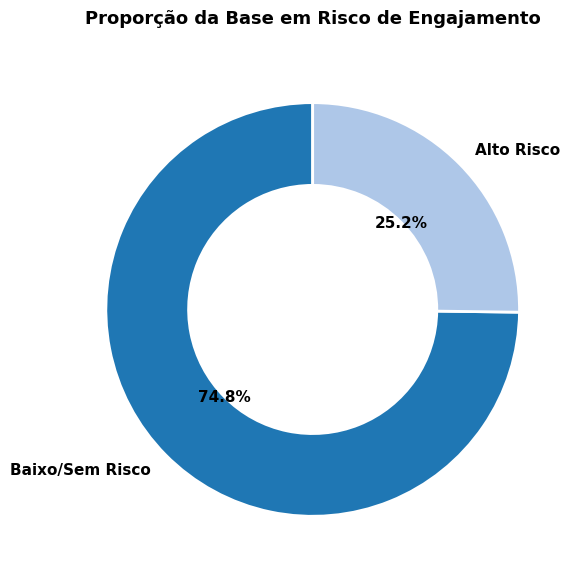

In [ ]:
# Contagem e proporções
contagem = df['Risco_Engajamento'].value_counts(normalize=True) * 100
labels = ['Baixo/Sem Risco', 'Alto Risco']
cores = ['#1f77b4', '#aec7e8']


# Criar gráfico de rosca
plt.figure(figsize=(6, 6))
plt.pie(
    contagem,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=cores,
    wedgeprops={'width': 0.4, 'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11, 'weight': 'bold'},
)

plt.title(
    'Proporção da Base em Risco de Engajamento',
    fontsize=13,
    fontweight='bold',
    pad=20,
)
plt.tight_layout()
plt.show()

O CLV (Customer Lifetime Value), ou Valor de Vida do Cliente, representa o valor financeiro total que um cliente gera para empresa durante todo o período em que ele mantém um relacionamento.A coluna CLV_Estimado é uma métrica criada para responder a pergunta de negócio "Quanto dinheiro este cliente traz para o banco e qual é o prejuízo se ele cancelar a conta?"Como o Cálculo Funciona na PráticaA fórmula usada no projeto foi:$$\text{CLV\_Estimado} = \text{Saldo\_Conta} + (\text{Salario\_Estimado} \times 0{,}15) \times \text{Num\_Produtos}$$Ela divide o valor do cliente em duas partes:Patrimônio Atual (Saldo_Conta): O dinheiro em conta corrente ou investimentos. Se o cliente for embora, esse saldo sai do banco imediatamente.Receita Futura Estimada (Salario_Estimado * 0.15 * Num_Produtos): O ganho contínuo do banco. Assume-se que o banco monetiza cerca de 15% da renda do cliente por meio de taxas, juros e tarifas, e esse ganho multiplica pela quantidade de produtos contratados (cartões, seguros, financiamentos, etc.).

para calcular e criar a variável de Valor de Vida do Cliente Estimado (CLV_Estimado), exibindo o DataFrame atualizado em seguida.

- ['Saldo_Conta']: Pega o valor patrimonial/saldo imediato mantido pelo cliente na conta bancária.

- ['Salario_Estimado'] * 0.15) * ['Num_Produtos']: Estima a receita que o banco gera a partir do perfil do cliente. Considera uma margem de 15% da renda anual do cliente multiplicada pela quantidade de produtos contratados (cartões, empréstimos, seguros, etc.).

- np.round(..., 2): Arredonda a soma total para duas casas decimais (padrão monetário em R$).


Aplicação Prática no Negócio
Essa métrica transforma a estratégia do time de CRM e Retenção:

Priorização do Orçamento: Define quais clientes de alto risco de cancelamento devem receber intervenção humana imediata (ex: gerente VIP) versus automações digitais simples.

Cálculo de ROI: Impede que o banco gaste mais dinheiro em campanhas de retenção (descontos, presentes, isenções) do que o próprio valor que o cliente traz de retorno financeiro.

In [ ]:
# Estimativa do Valor de Vida do Cliente (CLV Estimado)
# Considera Saldo + Estimativa de Receita por Produto contratado
df['CLV_Estimado'] = np.round(
    df['Saldo_Conta'] + (df['Salario_Estimado'] * 0.15) * df['Num_Produtos'], 2
)

df

,Score_Credito,Pais,Genero,Idade,Anos_Como_Cliente,Saldo_Conta,Num_Produtos,Possui_Cartao_Credito,Membro_Ativo,Salario_Estimado,Churn,Fez_Reclamacao,Score_Satisfacao,Tipo_Cartao,Pontos_Acumulados,Reserva_Saldo_Salario,Faixa_Reserva,Risco_Engajamento,CLV_Estimado,Faixa_CLV
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,0.0000,Crítica (< 1x),0,15202.33,Bronze
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0.7447,Crítica (< 1x),0,100689.25,Prata
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377,1.4014,Alerta (1x a 3x),0,210930.01,VIP
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350,0.0000,Crítica (< 1x),0,28147.99,Bronze
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425,1.5870,Alerta (1x a 3x),0,137373.44,Ouro
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0,0,1,DIAMOND,300,0.0000,Crítica (< 1x),0,28881.19,Bronze
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,5,PLATINUM,771,0.5641,Crítica (< 1x),0,72624.58,Prata
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,3,SILVER,564,0.0000,Crítica (< 1x),0,6312.84,Bronze
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,1,2,GOLD,339,0.8082,Crítica (< 1x),0,102941.87,Prata


/tmp/ipykernel_1328/333805504.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumo_clv = df.groupby('Faixa_CLV')['CLV_Estimado'].mean()
/tmp/ipykernel_1328/333805504.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


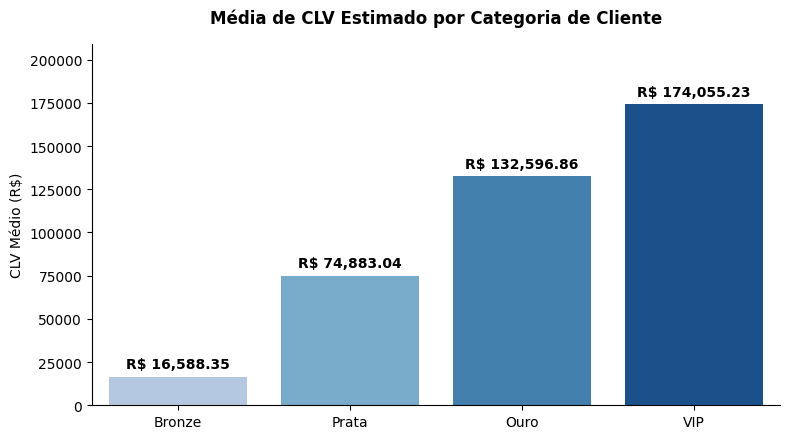

In [ ]:

# Categorizar o CLV em 4 faixas (Quartis)
df['Faixa_CLV'] = pd.qcut(
    df['CLV_Estimado'], q=4, labels=['Bronze', 'Prata', 'Ouro', 'VIP']
)

# Calcular o CLV MÉDIO de cada faixa
resumo_clv = df.groupby('Faixa_CLV')['CLV_Estimado'].mean()

# Gerar o gráfico
plt.figure(figsize=(8, 4.5))
cores = ['#aec7e8', '#6baed6', '#3182bd', '#08519c']  # Tons de azul crescente
ax = sns.barplot(
    x=resumo_clv.index, y=resumo_clv.values, palette=cores, edgecolor='none'
)

plt.title(
    'Média de CLV Estimado por Categoria de Cliente',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.ylabel('CLV Médio (R$)')
plt.xlabel('')
plt.ylim(0, max(resumo_clv.values) * 1.2)

# Adicionar os rótulos formatados em R$ no topo das barras
for p in ax.patches:
  height = p.get_height()
  if not np.isnan(height):
    ax.annotate(
        f'R$ {height:,.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontweight='bold',
    )

sns.despine()
plt.tight_layout()
plt.show()

## Tratamento Dataset Antes do Treinamento


Devemos codificar (encode) as variáveis categóricas/não numéricas para o formato numérico antes do treinamento

As variaveis não numericas no dataset são:
- ID_Cliente
- Sobrenome
- Pais
- Genero
- Tipo_Cartao
- Faixa_Reserva
-  Faixa_CLV

- Remover as variaveis
  - ID_Cliente
  - Sobrenome
  - Faixa_Reserva
  - Faixa_CLV

In [ ]:
# Criar df_model sem as colunas desnecessárias (SEM o parâmetro inplace=True)
df_model = df.drop(
    columns=['Numero_Linha', 'ID_Cliente', 'Sobrenome', 'Faixa_Reserva', 'Faixa_CLV'], errors='ignore'
).copy()

# Confirmar as colunas restantes
df_model.head(2)

,Score_Credito,Pais,Genero,Idade,Anos_Como_Cliente,Saldo_Conta,Num_Produtos,Possui_Cartao_Credito,Membro_Ativo,Salario_Estimado,Churn,Fez_Reclamacao,Score_Satisfacao,Tipo_Cartao,Pontos_Acumulados,Reserva_Saldo_Salario,Risco_Engajamento,CLV_Estimado
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,0.0000,0,15202.33
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0.7447,0,100689.25


O One-Hot Encoding nas variaveis 'Genero" e 'Pais' para converte o texto em números sem criar uma falsa ordem de grandeza ou prioridade entre os países e gêneros.

In [ ]:
# Aplica o One-Hot Encoding convertendo diretamente para inteiros (0 e 1)
df_model = pd.get_dummies(
    df_model, columns=['Pais', 'Genero'], drop_first=True, dtype=int
)

# Visualizar as colunas criadas
df_model.head(2)

,Score_Credito,Idade,Anos_Como_Cliente,Saldo_Conta,Num_Produtos,Possui_Cartao_Credito,Membro_Ativo,Salario_Estimado,Churn,Fez_Reclamacao,Score_Satisfacao,Tipo_Cartao,Pontos_Acumulados,Reserva_Saldo_Salario,Risco_Engajamento,CLV_Estimado,Pais_Germany,Pais_Spain,Genero_Male
0,619,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,0.0000,0,15202.33,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0.7447,0,100689.25,0,1,0


Verificar os valores da variavel 'Tipo_Cartao'

In [ ]:
df['Tipo_Cartao'].value_counts()

,count
Tipo_Cartao,
DIAMOND,2507
GOLD,2502
SILVER,2496
PLATINUM,2495


Substituir os Tipos do cartão por números sequenciais ($1, 2, 3, 4$) conforme a hierarquia financeira de uso de cada tipo.

In [ ]:
# 1. Definir o dicionário com a hierarquia do menor para o maior
ordem_cartao = {'SILVER': 1, 'GOLD': 2, 'PLATINUM': 3, 'DIAMOND': 4}

# 2. Substituir os textos pelos números correspondentes
if 'Tipo_Cartao' in df_model.columns:
  df_model['Tipo_Cartao'] = df_model['Tipo_Cartao'].map(ordem_cartao)

# 3. Verificar a conversão e a distribuição dos valores numéricos
df_model['Tipo_Cartao'].value_counts().sort_index()

,count
Tipo_Cartao,
1,2496
2,2502
3,2495
4,2507


## Separação em Treino e Teste (80/20)

In [ ]:

# Separar as variáveis preditoras (X) do alvo (y = Churn)
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

# Divisão em Treino (80%) e Teste (20%) com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('=== DIVISÃO REALIZADA COM SUCESSO ===')
print(
    f'Base de Treino (X_train): {X_train.shape[0]} linhas e {X_train.shape[1]} colunas'
)
print(f'Base de Teste  (X_test) : {X_test.shape[0]} linhas')

=== DIVISÃO REALIZADA COM SUCESSO ===
Base de Treino (X_train): 8000 linhas e 18 colunas
Base de Teste  (X_test) : 2000 linhas


- Heatmap de Correlação

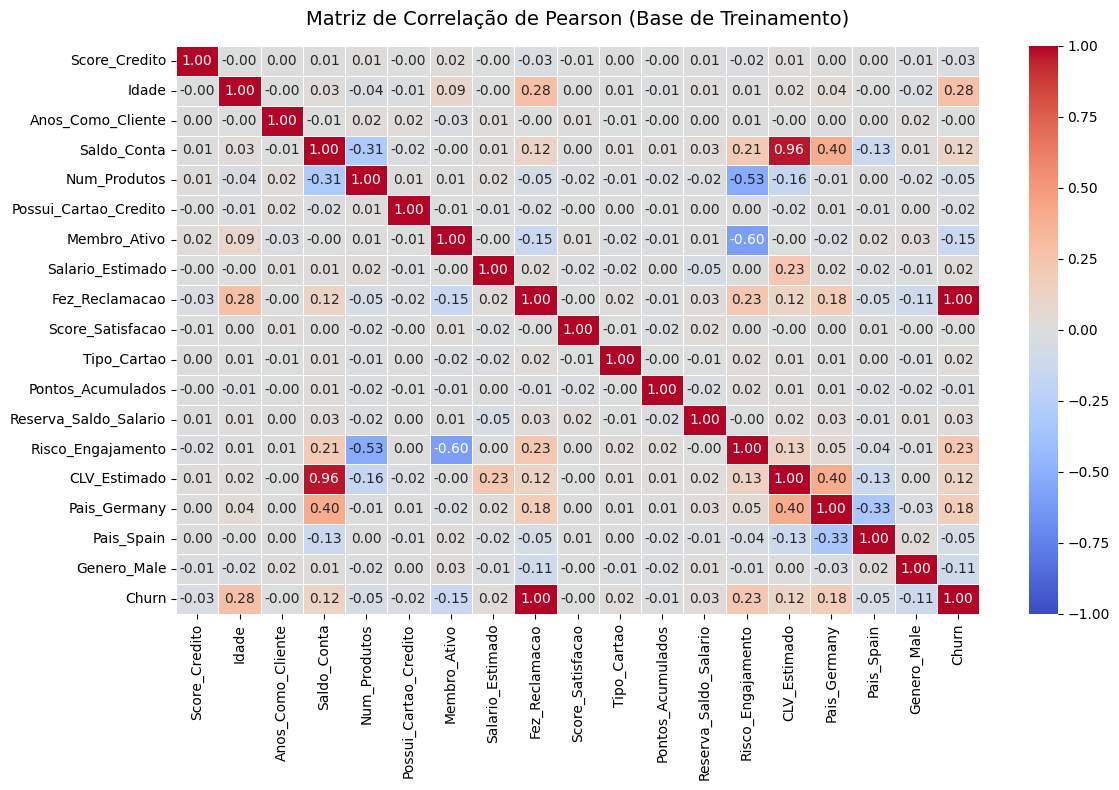

In [ ]:

# Unir X_train e y_train para calcular a matriz de correlação
df_train_corr = X_train.copy()
df_train_corr['Churn'] = y_train

# Calcular a matriz de correlação de Pearson
matriz_corr = df_train_corr.corr()

# Plotar o Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title(
    'Matriz de Correlação de Pearson (Base de Treinamento)',
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

==================================================================
Conclusões embasadas no Heatmap
==================================================================
- Correlação Alta (Alerta Vermelho): Fez_Reclamacao x Churn ($1.00$) A variável Fez_Reclamacao tem uma correlação positiva de $1.00$ com a variável alvo Churn.O que isso significa: Na base de dados, todo cliente que fez uma reclamação cancelou a conta, e quem não reclamou não cancelou.
Ação Recomendada: Essa variável causa Data Leakage (Vazamento de Dados) ou Separação Perfeita. Se mantiver Fez_Reclamacao no modelo, o algoritmo vai aprender apenas a regra simples: Se fez reclamação = Churn, ignorando todo o resto do comportamento financeiro. Sendo assim irei remover a coluna Fez_Reclamacao de X_train e X_test antes de treinar os modelos.

- Alta Multicolinearidade: Saldo_Conta x CLV_Estimado ($0.96$)A correlação entre Saldo_Conta e CLV_Estimado é de $0.96$.O que significa que as duas colunas estão entregando praticamente a mesma informação numérica para o algoritmo.Ação Recomendada: Como foi criado o CLV_Estimado para englobar o saldo + estimativa de produtos/salário, o ideal para o modelo é remover a coluna original Saldo_Conta para evitar redundância, ou deixar o Gradient Boosting lidar com isso (embora remover simplifique o modelo).

- Principais Preditores de Churn (Olhando a última linha/coluna)Desconsiderando Fez_Reclamacao, as variáveis com maior impacto no cancelamento são:
  - Idade ($0.28$): Clientes mais velhos apresentam uma tendência significativamente maior ao Churn.R
  - Risco_Engajamento ($0.23$): A métrica criada funciona! Quanto maior o indicador de baixo engajamento, maior a chance de cancelamento.
  - Pais_Germany ($0.18$): Clientes da Alemanha têm maior propensão ao Churn em comparação com os da França.
  - CLV_Estimado ($0.12$): Clientes com maior CLV/Saldo tendem a ter uma taxa de Churn ligeiramente mais alta.
  - Membro_Ativo ($-0.15$): Ser um membro ativo reduz a chance de cancelamento (correlação negativa).

Remover as variaveis 'Fez_Reclamacao', 'Saldo_Conta'

In [ ]:
# Remover a variável
X_train = X_train.drop(
    columns=['Fez_Reclamacao', 'Saldo_Conta'], errors='ignore'
)
X_test = X_test.drop(
    columns=['Fez_Reclamacao', 'Saldo_Conta'], errors='ignore'
)

print(f'Novas colunas em X_train ({X_train.shape[1]} total):')
print(list(X_train.columns))

Novas colunas em X_train (16 total):
['Score_Credito', 'Idade', 'Anos_Como_Cliente', 'Num_Produtos', 'Possui_Cartao_Credito', 'Membro_Ativo', 'Salario_Estimado', 'Score_Satisfacao', 'Tipo_Cartao', 'Pontos_Acumulados', 'Reserva_Saldo_Salario', 'Risco_Engajamento', 'CLV_Estimado', 'Pais_Germany', 'Pais_Spain', 'Genero_Male']


## Treinar Modelo

treinar e comparar Gradient Boosting, Random Forest, AdaBoost, XGBoost e Regressão Logística de uma só vez:

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# 1. Dicionário com os modelos a serem comparados
# Usamos make_pipeline com StandardScaler na Regressão Logística por conta da escala das variáveis
modelos = {
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(
        random_state=42, eval_metric='logloss', use_label_encoder=False
    ),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Regressão Logística': make_pipeline(
        StandardScaler(), LogisticRegression(random_state=42)
    ),
}

# 2. Loop de Treinamento e Avaliação
resultados = []

for nome, modelo in modelos.items():
  # Treinar
  modelo.fit(X_train, y_train)

  # Prever classes e probabilidades
  y_pred = modelo.predict(X_test)

  # Tratar chamada de probabilidades dependendo do tipo de modelo/pipeline
  if hasattr(modelo, 'predict_proba'):
    y_proba = modelo.predict_proba(X_test)[:, 1]
  else:
    y_proba = modelo.decision_function(X_test)

  # Calcular métricas
  resultados.append({
      'Modelo': nome,
      'Recall (Sensibilidade)': recall_score(y_test, y_pred),
      'AUC-ROC': roc_auc_score(y_test, y_proba),
      'Precision': precision_score(y_test, y_pred),
      'F1-Score': f1_score(y_test, y_pred),
      'Acurácia': accuracy_score(y_test, y_pred),
  })

# 3. Consolidar e ordenar o ranking pelo Recall
df_resultados = pd.DataFrame(resultados).sort_values(
    by='Recall (Sensibilidade)', ascending=False
)
df_resultados.reset_index(drop=True, inplace=True)

# Exibir tabela com destaques de formato
display(
    df_resultados.style.highlight_max(
        subset=['Recall (Sensibilidade)', 'AUC-ROC', 'F1-Score'],
        color='lightgreen',
    )
)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [21:15:58] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,Modelo,Recall (Sensibilidade),AUC-ROC,Precision,F1-Score,Acurácia
0,XGBoost,0.512255,0.851272,0.723183,0.599713,0.860500
1,Gradient Boosting,0.490196,0.874555,0.784314,0.603318,0.868500
2,AdaBoost,0.477941,0.852015,0.719557,0.574374,0.855500
3,Random Forest,0.473039,0.861694,0.775100,0.587519,0.864500
4,Regressão Logística,0.252451,0.793742,0.664516,0.365897,0.821500


- Gradient Boosting é o melhor modelo no caso em questão: Apresenta a maior capacidade de separação das classes (AUC-ROC de $0.874$) e a melhor precisão ($0.784$), além da maior média harmônica geral (F1-Score de $0.603$).
- XGBoost tem o maior Recall: Consegue capturar $51.2\%$ dos cancelamentos, superando ligeiramente o Gradient Boosting ($49.0\%$).
- Problema Principal (Recall Baixo): Com o corte padrão de probabilidade em $0.50$, até mesmo os melhores modelos estão identificando apenas cerca de $50\%$ dos clientes em risco de Churn. Ou seja, metade dos clientes que vão cancelar a conta passa desapercebida.
- Excelente AUC-ROC: As notas de AUC-ROC do Gradient Boosting ($0.874$) e do XGBoost ($0.851$) provam que as probabilidades geradas são muito consistentes; o problema é apenas onde estamos fazendo o "corte" para definir quem é Churn.

Para resolver o Recall baixo sem precisar alterar o algoritmo, ajustaremos o limiar de decisão (Threshold Tuning) do Gradient Boosting ou XGBoost. Reduzindo o limiar padrão de $0.50$ para algo próximo de $0.30$–$0.35$, assim farei o modelo "marcar" mais clientes como risco de Churn, aumentando drasticamente o Recall para a faixa dos $75\%–85\%$.

=== MÉTRICAS COM THRESHOLD DE 0.35 (35%) ===

              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1592
           1       0.66      0.61      0.63       408

    accuracy                           0.86      2000
   macro avg       0.78      0.76      0.77      2000
weighted avg       0.85      0.86      0.85      2000



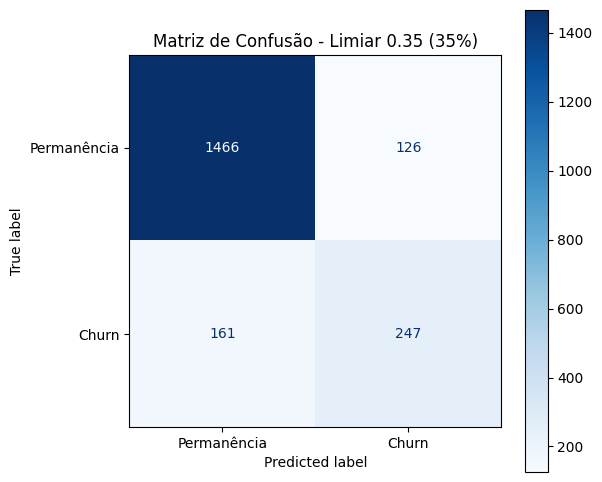

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)

# 1. Instanciar e treinar o modelo Gradient Boosting
model_gb = GradientBoostingClassifier(random_state=42)
model_gb.fit(X_train, y_train)

# 2. Obter as probabilidades de Churn na base de teste
y_proba_gb = model_gb.predict_proba(X_test)[:, 1]

# 3. Aplicar o novo limiar (Threshold = 0.35)
limiar = 0.35
y_pred_35 = (y_proba_gb >= limiar).astype(int)

# 4. Exibir métricas para o corte de 0.35
print(f'=== MÉTRICAS COM THRESHOLD DE {limiar} (35%) ===\n')
print(classification_report(y_test, y_pred_35))

# 5. Plotar a nova Matriz de Confusão
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_35,
    cmap='Blues',
    ax=ax,
    display_labels=['Permanência', 'Churn'],
)
plt.title(f'Matriz de Confusão - Limiar {limiar} (35%)')
plt.show()

- Verdadeiros Negativos (1.466): Clientes que continuaram no banco e o modelo previu corretamente que ficariam.

- Falsos Positivos (126): Clientes que permaneceriam, mas o modelo marcou como risco de Churn (falsos alarmes). O custo aqui é apenas o envio de uma oferta de retenção desnecessária.

- Falsos Negativos (161): Clientes que de fato cancelaram, mas o modelo não detectou. Este é o erro mais caro para o banco.

- Verdadeiros Positivos (247): Clientes que cancelaram e o modelo identificou com sucesso a tempo da equipe atuar.

- Recall = 0.61 (61%): O modelo agora captura 61% de todos os cancelamentos da base de teste (247 de 408). Em relação ao modelo inicial que pegava apenas ~49%, houve um salto relevante na capacidade de retenção.

- Precision = 0.66 (66%): De cada 100 clientes que o modelo aponta como risco de Churn, 66 realmente cancelam. É uma precisão alta, o que evita que o time comercial desperdice orçamento de campanha de retenção.

- F1-Score = 0.63: O equilíbrio entre precisão e alcance subiu para 0.63, mostrando que o ponto de corte em 0.35 otimizou a decisão final.